# EP 1 MQAM


In [1]:
# Import das bibliotecas utilizadas no projeto

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import norm
from statsmodels.stats.diagnostic import het_breuschpagan
import os
from pathlib import Path
from dotenv import load_dotenv, find_dotenv

In [2]:
load_dotenv(find_dotenv(usecwd=True)) 
DATA_DIR = Path(os.getenv("DATA_DIR", "../datasets"))

## Dataset 'Treadwear'

In [3]:
df = pd.read_csv(DATA_DIR / "treadwear.txt", sep="\t")
df = df[["mileage", "groove"]].copy()

# Conversão e Tratamento dos dados
for coluna in ["mileage", "groove"]:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

df = df.dropna().drop_duplicates().reset_index(drop=True)

### Gráficos - Dataframe Original

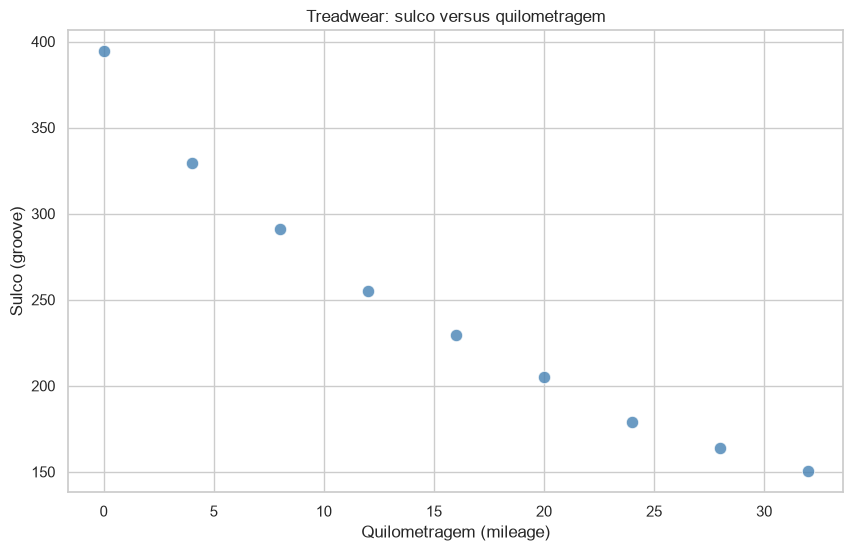


RESULTADOS DA REGRESSÃO LINEAR
                            OLS Regression Results                            
Dep. Variable:                 groove   R-squared:                       0.953
Model:                            OLS   Adj. R-squared:                  0.946
Method:                 Least Squares   F-statistic:                     140.7
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           6.87e-06
Time:                        13:14:24   Log-Likelihood:                -38.148
No. Observations:                   9   AIC:                             80.30
Df Residuals:                       7   BIC:                             80.69
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        360.636

,Coeficiente,Erro-padrão,Estatística t,P-valor,IC 95% inferior,IC 95% superior
const,360.6367,11.6886,30.8538,0.0,332.9976,388.2757
mileage,-7.2806,0.6138,-11.8621,0.0,-8.7320,-5.8293


R²: 0.9526
R² ajustado: 0.9458


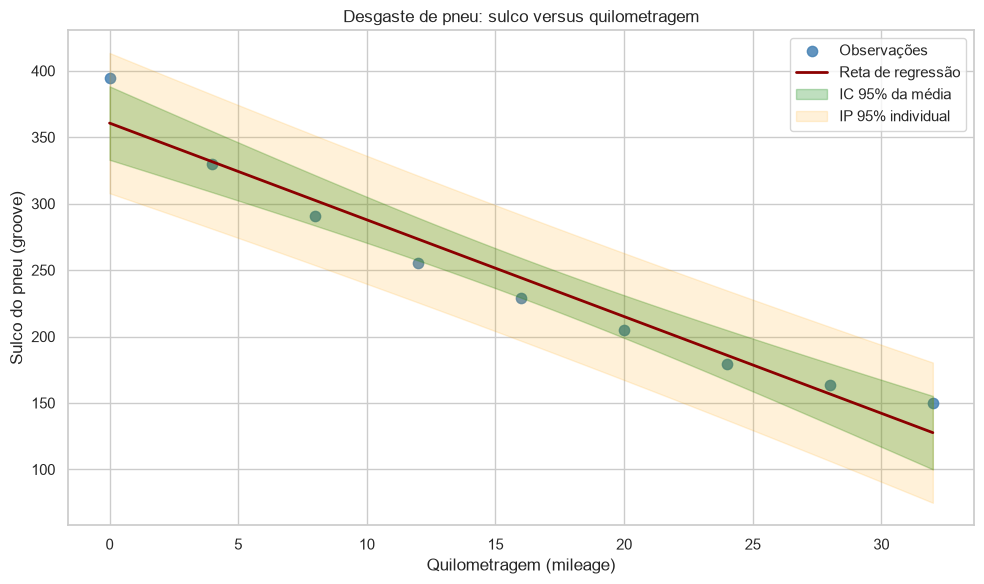

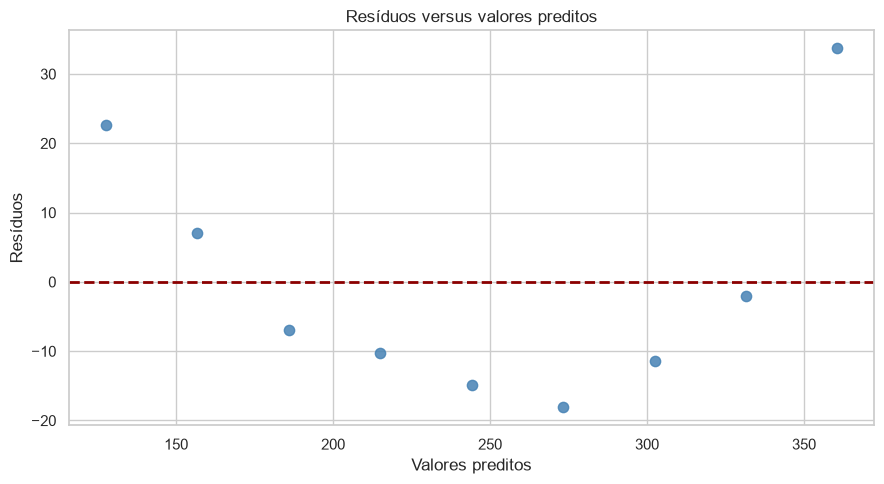

<Figure size 700x700 with 0 Axes>

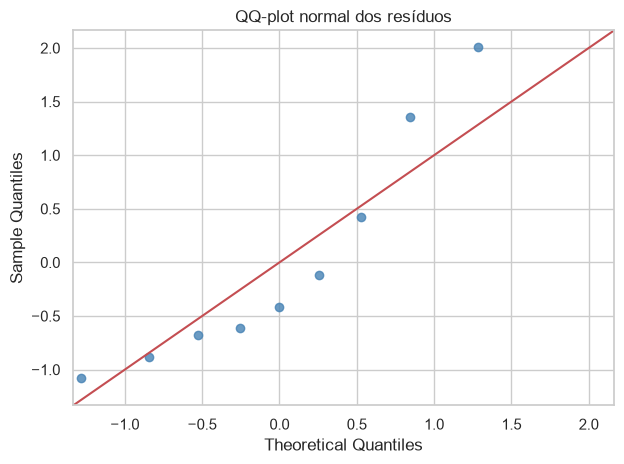


TESTE DE BREUSCH-PAGAN (COMPLEMENTAR)
Estatística LM: 1.0910
P-valor LM: 0.2962
Não há evidência estatística suficiente de heterocedasticidade (5%).


c:\Users\beatr\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


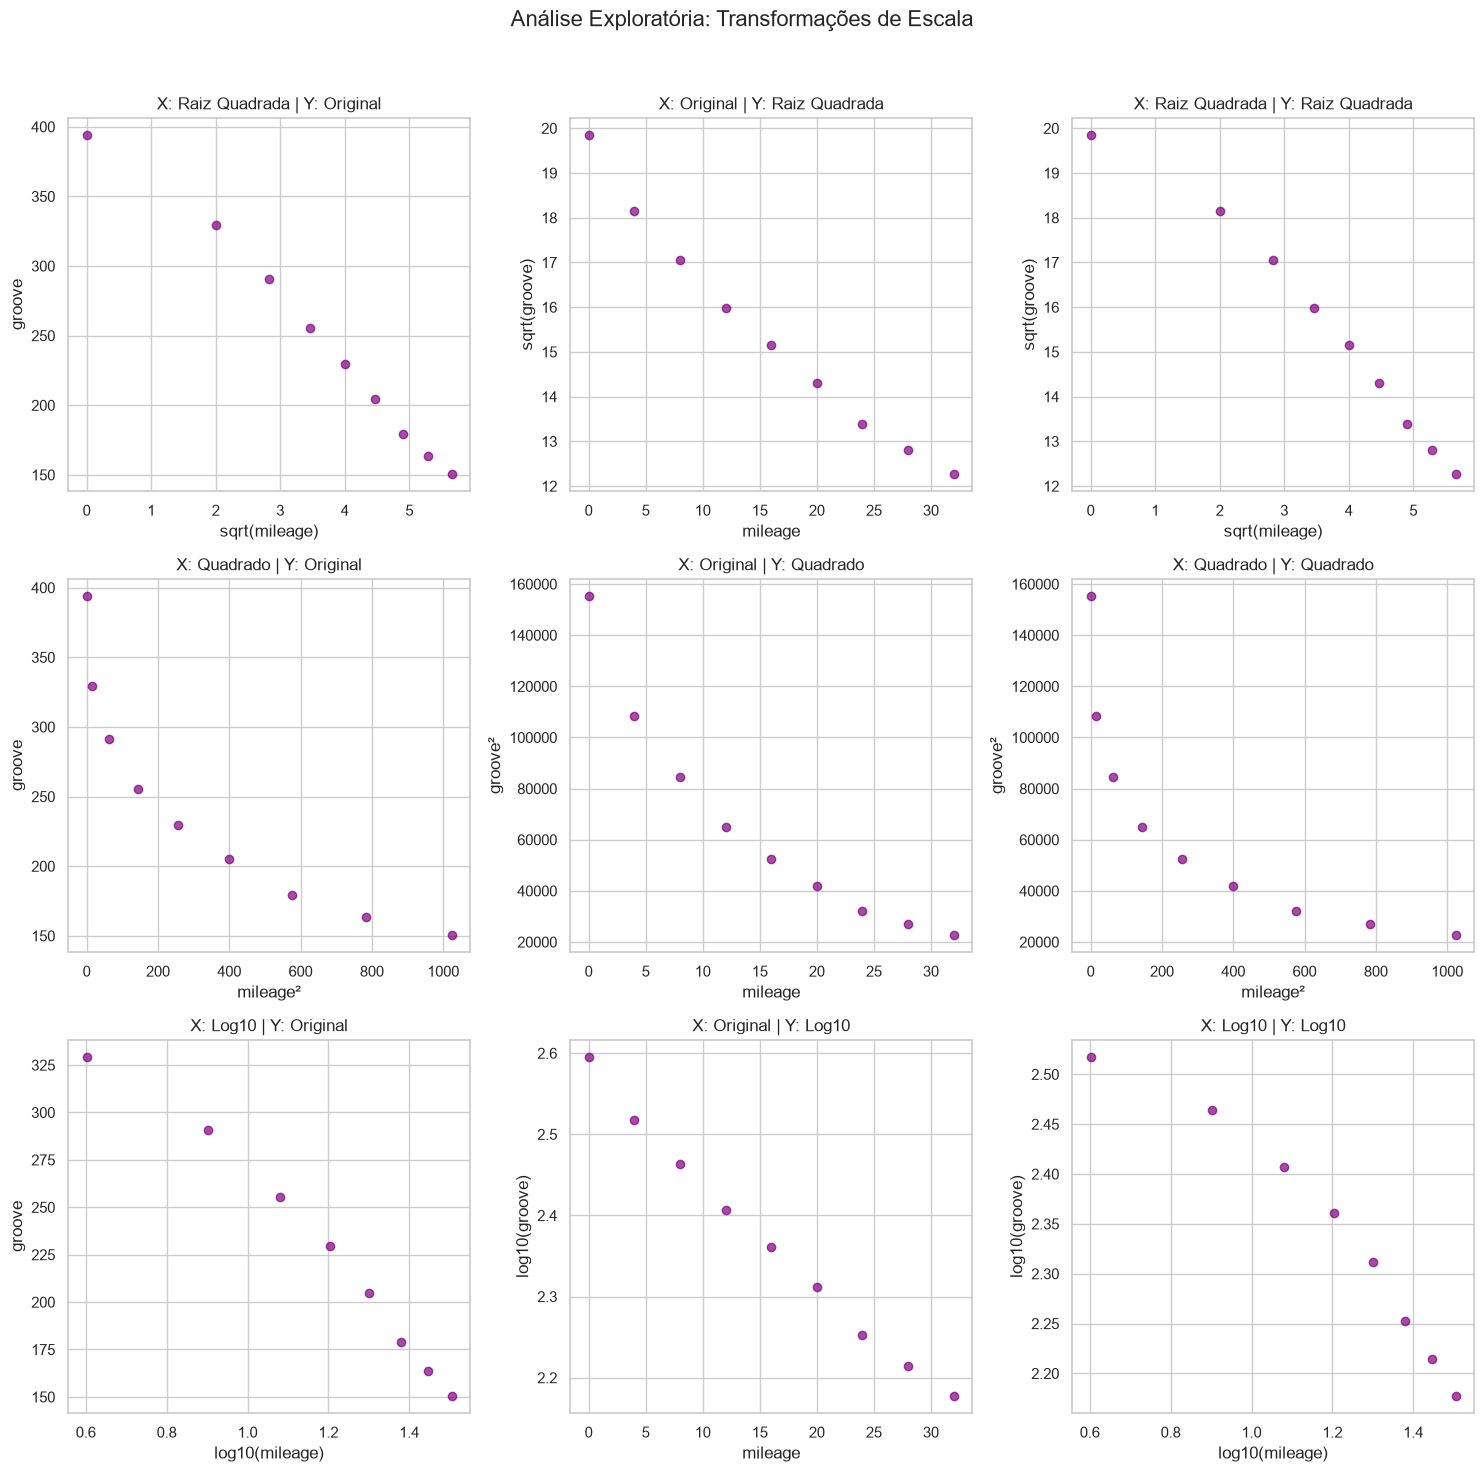

In [12]:
# Etapa 3.1: regressão sobre os dados originais
# Padrão visual dos gráficos
sns.set_theme(style="whitegrid", context="notebook")

# Dispersão simples de groove versus mileage (sem reta)
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='mileage',
    y='groove',
    s=80,
    alpha=0.8,
    color='steelblue',
    edgecolor='w'
)

plt.title('Treadwear: sulco versus quilometragem')
plt.xlabel('Quilometragem (mileage)')
plt.ylabel('Sulco (groove)')
plt.show()

# Ajuste do modelo de regressão linear simples (MQO): groove em função de mileage
X = sm.add_constant(df["mileage"])
Y = df["groove"]

modelo = sm.OLS(Y, X).fit()

df["predito"] = modelo.fittedvalues
df["residuo"] = modelo.resid

# Resumo completo do ajuste
print("\nRESULTADOS DA REGRESSÃO LINEAR")
print(modelo.summary())

# Tabela de coeficientes, erros-padrão, estatísticas t, p-valores e IC 95%
tabela_coef = pd.DataFrame({
    "Coeficiente": modelo.params,
    "Erro-padrão": modelo.bse,
    "Estatística t": modelo.tvalues,
    "P-valor": modelo.pvalues,
    "IC 95% inferior": modelo.conf_int()[0],
    "IC 95% superior": modelo.conf_int()[1]
})

print("\nCOEFICIENTES E INTERVALOS DE CONFIANÇA")
display(tabela_coef.round(4))

# Coeficiente de determinação (R²) e R² ajustado
print(f"R²: {modelo.rsquared:.4f}")
print(f"R² ajustado: {modelo.rsquared_adj:.4f}")

# Grade de valores de X e previsões com IC 95% da média e IP 95%
x_grade = np.linspace(df["mileage"].min(), df["mileage"].max(), 200)

X_grade = sm.add_constant(x_grade)

previsoes = modelo.get_prediction(X_grade).summary_frame(alpha=0.05)

# Dispersão com reta de regressão, IC 95% da média e IP 95%
plt.figure(figsize=(10, 6))

plt.scatter(
    df["mileage"], df["groove"],
    color="steelblue", s=55, alpha=0.85,
    label="Observações"
)

plt.plot(
    x_grade, previsoes["mean"],
    color="darkred", linewidth=2,
    label="Reta de regressão"
)

plt.fill_between(
    x_grade,
    previsoes["mean_ci_lower"],
    previsoes["mean_ci_upper"],
    color="green", alpha=0.25,
    label="IC 95% da média"
)

plt.fill_between(
    x_grade,
    previsoes["obs_ci_lower"],
    previsoes["obs_ci_upper"],
    color="orange", alpha=0.15,
    label="IP 95% individual"
)

plt.xlabel("Quilometragem (mileage)")
plt.ylabel("Sulco do pneu (groove)")
plt.title("Desgaste de pneu: sulco versus quilometragem")
plt.legend()
plt.tight_layout()
plt.show()

# Resíduos
residuos = df["residuo"].to_numpy()

# Resíduos versus valores preditos
plt.figure(figsize=(9, 5))

plt.scatter(
    df["predito"], df["residuo"],
    color="steelblue", s=55, alpha=0.85
)

plt.axhline(0, color="darkred", linestyle="--", linewidth=2)

plt.xlabel("Valores preditos")
plt.ylabel("Resíduos")
plt.title("Resíduos versus valores preditos")
plt.tight_layout()
plt.show()

# QQ-plot dos resíduos contra a distribuição normal
plt.figure(figsize=(7, 7))

sm.qqplot(
    residuos, line="45", fit=True,
    markerfacecolor="steelblue",
    markeredgecolor="steelblue",
    alpha=0.8
)

plt.title("QQ-plot normal dos resíduos")
plt.tight_layout()
plt.show()

# Teste de Breusch-Pagan (heterocedasticidade)
bp = het_breuschpagan(modelo.resid, modelo.model.exog)

print("\nTESTE DE BREUSCH-PAGAN (COMPLEMENTAR)")
print(f"Estatística LM: {bp[0]:.4f}")
print(f"P-valor LM: {bp[1]:.4f}")

if bp[1] < 0.05:
    print("Há evidência estatística de heterocedasticidade (5%).")
else:
    print("Não há evidência estatística suficiente de heterocedasticidade (5%).")

# Etapa 3.2: 9 combinações de transformações (raiz quadrada, quadrado e log10 em X, Y ou ambos)
fig, axs = plt.subplots(3, 3, figsize=(15, 15))
fig.suptitle("Análise Exploratória: Transformações de Escala", fontsize=16)

x = df["mileage"]
y = df["groove"]

combinacoes = [
    (np.sqrt(x), y, "X: Raiz Quadrada | Y: Original", "sqrt(mileage)", "groove"),
    (x, np.sqrt(y), "X: Original | Y: Raiz Quadrada", "mileage", "sqrt(groove)"),
    (np.sqrt(x), np.sqrt(y), "X: Raiz Quadrada | Y: Raiz Quadrada", "sqrt(mileage)", "sqrt(groove)"),
    (x**2, y, "X: Quadrado | Y: Original", "mileage²", "groove"),
    (x, y**2, "X: Original | Y: Quadrado", "mileage", "groove²"),
    (x**2, y**2, "X: Quadrado | Y: Quadrado", "mileage²", "groove²"),
    (np.log10(x), y, "X: Log10 | Y: Original", "log10(mileage)", "groove"),
    (x, np.log10(y), "X: Original | Y: Log10", "mileage", "log10(groove)"),
    (np.log10(x), np.log10(y), "X: Log10 | Y: Log10", "log10(mileage)", "log10(groove)")
]

for i, ax in enumerate(axs.flat):
    x_transf, y_transf, titulo, xlab, ylab = combinacoes[i]
    ax.scatter(x_transf, y_transf, color="purple", alpha=0.7)
    ax.set_title(titulo)
    ax.set_xlabel(xlab)
    ax.set_ylabel(ylab)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


### Gráficos - Dataframe após transformação


RESULTADOS DA REGRESSÃO LINEAR
                            OLS Regression Results                            
Dep. Variable:                 groove   R-squared:                       0.993
Model:                            OLS   Adj. R-squared:                  0.992
Method:                 Least Squares   F-statistic:                     976.3
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           8.88e-09
Time:                        13:14:40   Log-Likelihood:                 27.570
No. Observations:                   9   AIC:                            -51.14
Df Residuals:                       7   BIC:                            -50.75
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.573

,Coeficiente,Erro-padrão,Estatística t,P-valor,IC 95% inferior,IC 95% superior
const,2.5736,0.0079,326.5764,0.0,2.5550,2.5922
mileage,-0.0129,0.0004,-31.2456,0.0,-0.0139,-0.0120


R²: 0.9929
R² ajustado: 0.9919


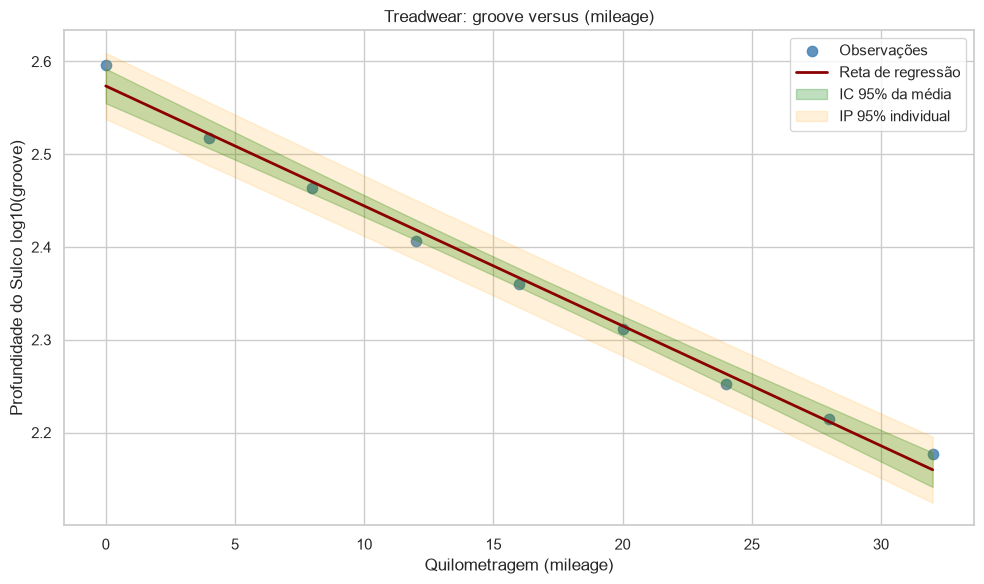

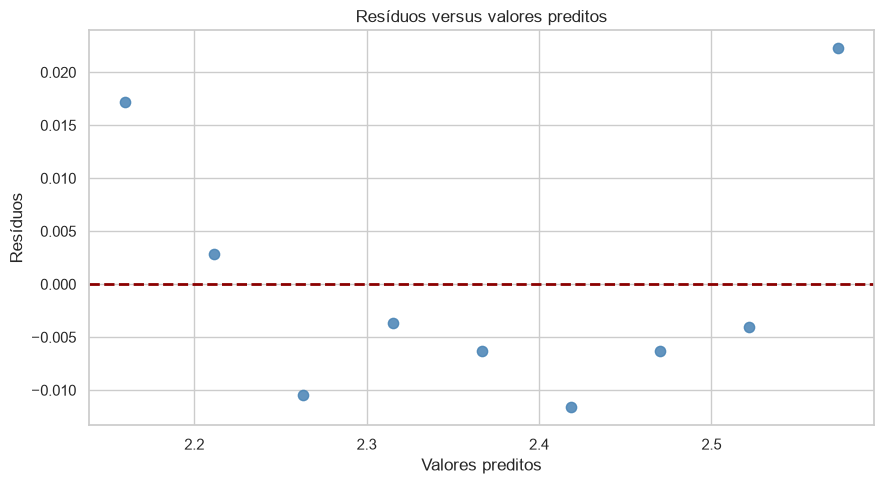

<Figure size 700x700 with 0 Axes>

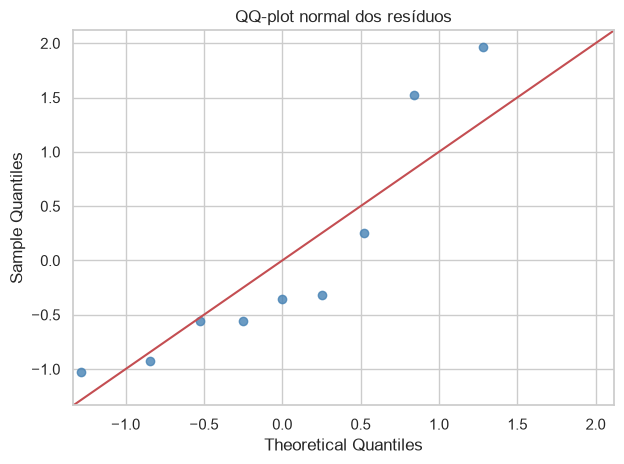


TESTE DE BREUSCH-PAGAN (COMPLEMENTAR)
Estatística LM: 0.4449
P-valor LM: 0.5048
Não há evidência estatística suficiente de heterocedasticidade (5%).


In [13]:
# Etapa 3.3: regressão com a transformação escolhida
# Transformação escolhida: mileage na escala original e log10 apenas em groove
df["mileage"] = (df["mileage"])

df["groove"] = np.log10(df["groove"])

# Ajuste do modelo de regressão linear simples (MQO): groove em função de mileage
X = sm.add_constant(df["mileage"])
Y = df["groove"]

modelo = sm.OLS(Y, X).fit()

df["predito"] = modelo.fittedvalues
df["residuo"] = modelo.resid

# Resumo completo do ajuste
print("\nRESULTADOS DA REGRESSÃO LINEAR")
print(modelo.summary())

# Tabela de coeficientes, erros-padrão, estatísticas t, p-valores e IC 95%
tabela_coef = pd.DataFrame({
    "Coeficiente": modelo.params,
    "Erro-padrão": modelo.bse,
    "Estatística t": modelo.tvalues,
    "P-valor": modelo.pvalues,
    "IC 95% inferior": modelo.conf_int()[0],
    "IC 95% superior": modelo.conf_int()[1]
})

print("\nCOEFICIENTES E INTERVALOS DE CONFIANÇA")
display(tabela_coef.round(4))

# Coeficiente de determinação (R²) e R² ajustado
print(f"R²: {modelo.rsquared:.4f}")
print(f"R² ajustado: {modelo.rsquared_adj:.4f}")

# Grade de valores de X e previsões com IC 95% da média e IP 95%
x_grade = np.linspace(df["mileage"].min(), df["mileage"].max(), 200)

X_grade = sm.add_constant(x_grade)

previsoes = modelo.get_prediction(X_grade).summary_frame(alpha=0.05)

# Dispersão com reta de regressão, IC 95% da média e IP 95%
plt.figure(figsize=(10, 6))

plt.scatter(
    df["mileage"], df["groove"],
    color="steelblue", s=55, alpha=0.85,
    label="Observações"
)

plt.plot(
    x_grade, previsoes["mean"],
    color="darkred", linewidth=2,
    label="Reta de regressão"
)

plt.fill_between(
    x_grade,
    previsoes["mean_ci_lower"],
    previsoes["mean_ci_upper"],
    color="green", alpha=0.25,
    label="IC 95% da média"
)

plt.fill_between(
    x_grade,
    previsoes["obs_ci_lower"],
    previsoes["obs_ci_upper"],
    color="orange", alpha=0.15,
    label="IP 95% individual"
)

plt.xlabel("Quilometragem (mileage)")
plt.ylabel("Profundidade do Sulco log10(groove)")
plt.title("Treadwear: groove versus (mileage)")
plt.legend()
plt.tight_layout()
plt.show()

# Resíduos do modelo transformado
residuos = df["residuo"].to_numpy()

# Resíduos versus valores preditos
plt.figure(figsize=(9, 5))

plt.scatter(
    df["predito"], df["residuo"],
    color="steelblue", s=55, alpha=0.85
)

plt.axhline(0, color="darkred", linestyle="--", linewidth=2)

plt.xlabel("Valores preditos")
plt.ylabel("Resíduos")
plt.title("Resíduos versus valores preditos")
plt.tight_layout()
plt.show()

# QQ-plot dos resíduos contra a distribuição normal
plt.figure(figsize=(7, 7))

sm.qqplot(
    residuos, line="45", fit=True,
    markerfacecolor="steelblue",
    markeredgecolor="steelblue",
    alpha=0.8
)

plt.title("QQ-plot normal dos resíduos")
plt.tight_layout()
plt.show()

# Teste de Breusch-Pagan (heterocedasticidade)
bp = het_breuschpagan(modelo.resid, modelo.model.exog)

print("\nTESTE DE BREUSCH-PAGAN (COMPLEMENTAR)")
print(f"Estatística LM: {bp[0]:.4f}")
print(f"P-valor LM: {bp[1]:.4f}")

if bp[1] < 0.05:
    print("Há evidência estatística de heterocedasticidade (5%).")
else:
    print("Não há evidência estatística suficiente de heterocedasticidade (5%).")


## Dataset 'Alligator'

In [4]:
# Definição de padrão visual para os gráficos
sns.set_theme(style="whitegrid", context="notebook")
plt.figure(figsize=(10, 6))

# Import do arquivo do Dataset

df = pd.read_csv(DATA_DIR / "alligator.txt", sep=r"\s+", encoding="utf-8-sig")
df.columns = df.columns.str.strip().str.lower()

df = df[["length", "weight"]].copy()
df = df.dropna().drop_duplicates().reset_index(drop=True)


<Figure size 1000x600 with 0 Axes>

### Gráficos - Dataframe Original

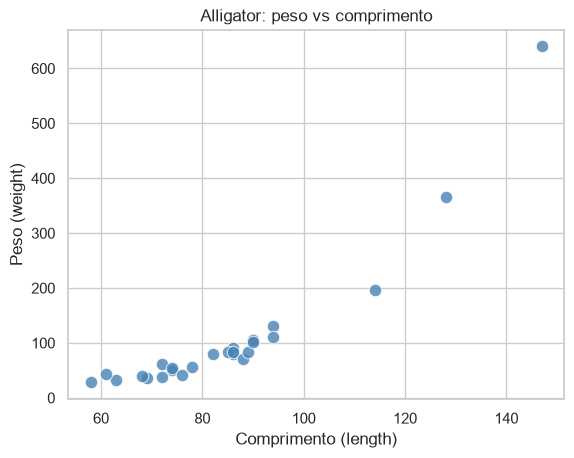


RESULTADOS DA REGRESSÃO LINEAR
                            OLS Regression Results                            
Dep. Variable:                 weight   R-squared:                       0.836
Model:                            OLS   Adj. R-squared:                  0.829
Method:                 Least Squares   F-statistic:                     117.4
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           1.65e-10
Time:                        13:17:25   Log-Likelihood:                -134.16
No. Observations:                  25   AIC:                             272.3
Df Residuals:                      23   BIC:                             274.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -393.264

,Coeficiente,Erro-padrão,Estatística t,P-valor,IC 95% inferior,IC 95% superior
const,-393.2640,47.5341,-8.2733,0.0,-491.5958,-294.9323
length,5.9024,0.5448,10.8330,0.0,4.7752,7.0295


R²: 0.8361
R² ajustado: 0.8290


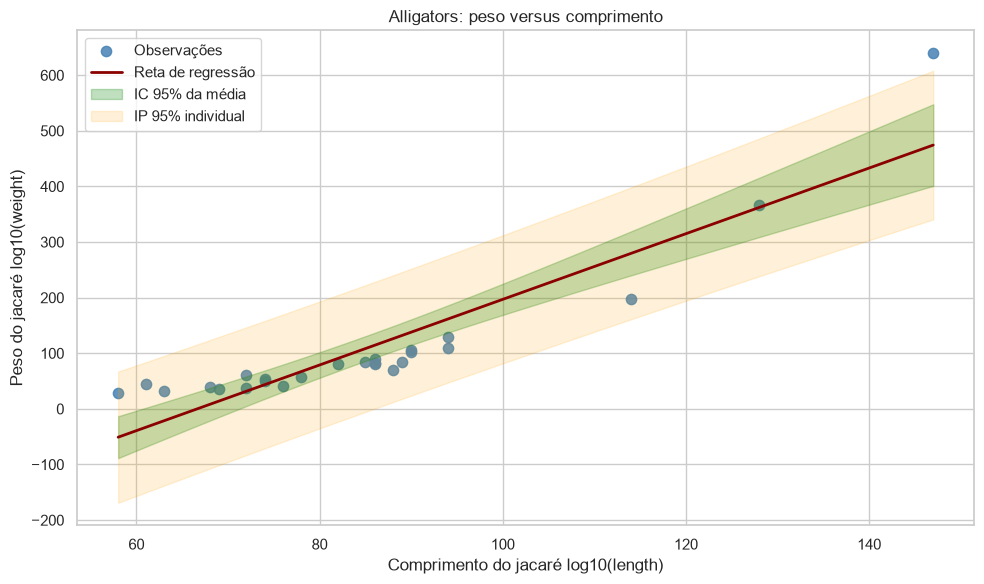

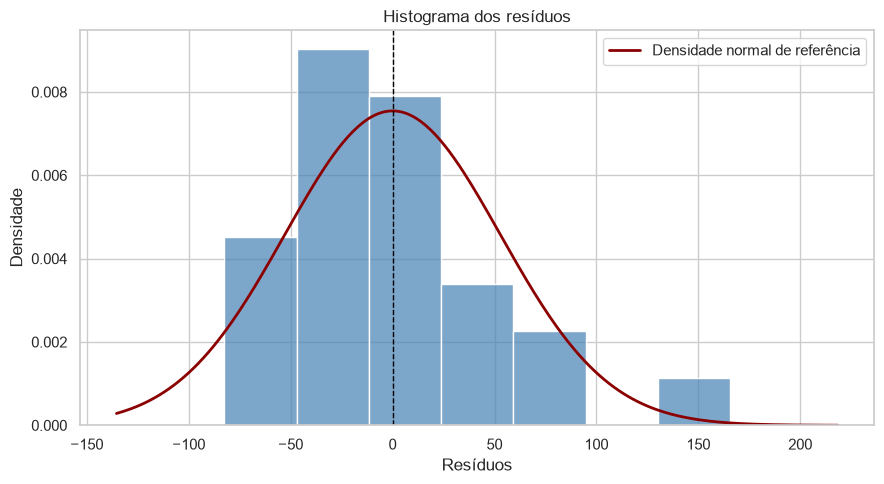

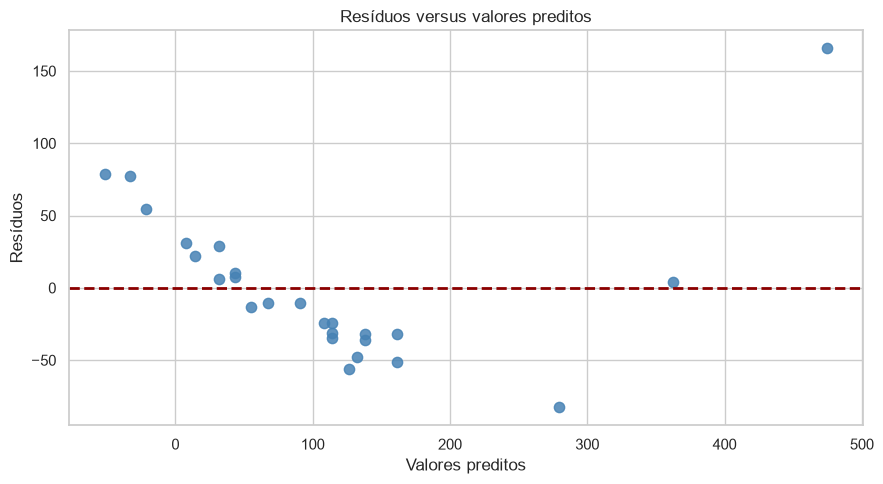

<Figure size 700x700 with 0 Axes>

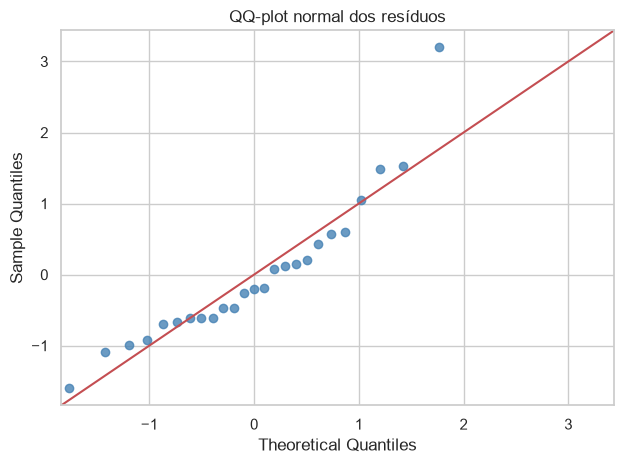


TESTE DE BREUSCH-PAGAN (COMPLEMENTAR)
Estatística LM: 8.3498
P-valor LM: 0.0039
Há evidência estatística de heterocedasticidade (5%).


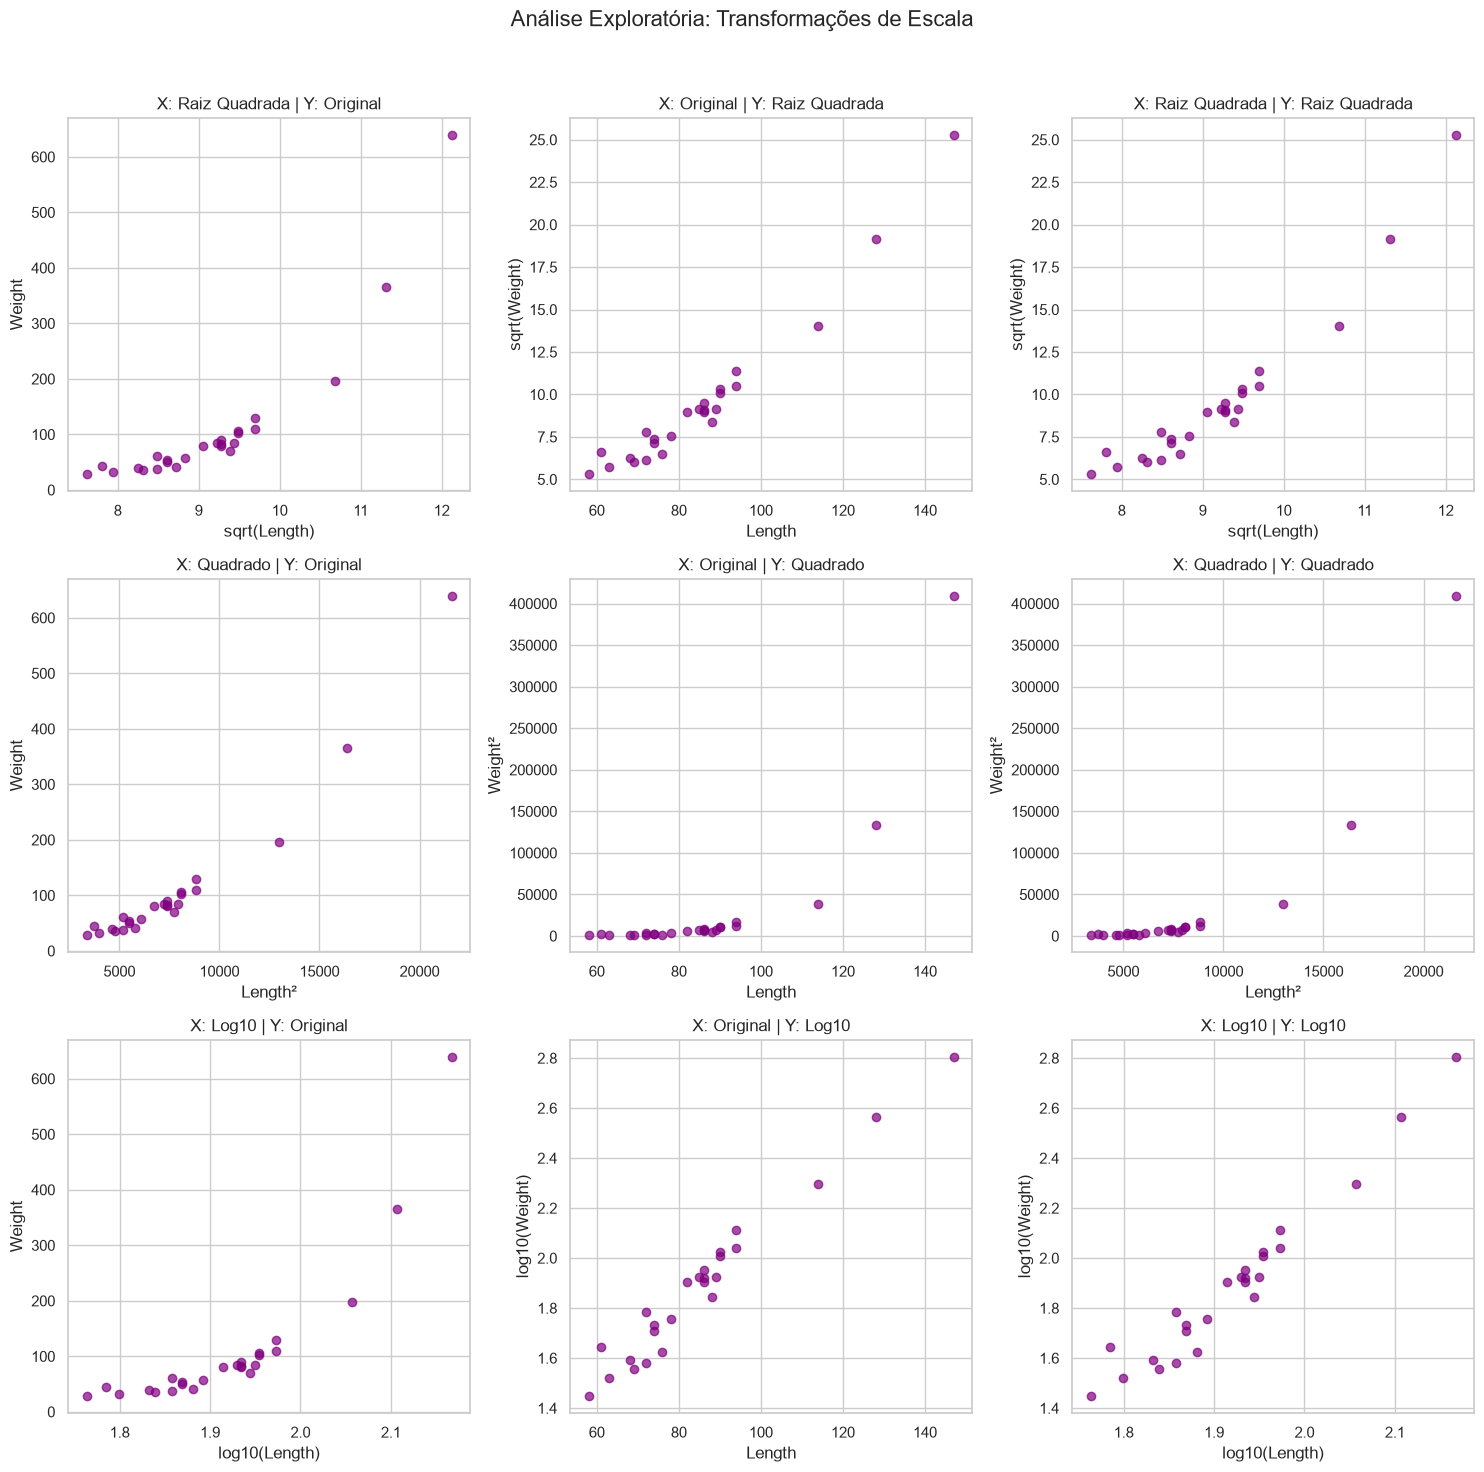

In [16]:
# Gráfico de Dispersão
sns.scatterplot(
    data=df,
    x='length',
    y='weight',
    s=80,
    alpha=0.8,
    color='steelblue',
    edgecolor='w'
)

plt.title('Alligator: peso vs comprimento')
plt.xlabel('Comprimento (length)')
plt.ylabel('Peso (weight)')

plt.savefig('dispersao_simples_original.png', dpi=300, bbox_inches='tight')
plt.show()

# Mínimos Quadrados Ordinários - OLS

X = sm.add_constant(df["length"])
Y = df["weight"]

modelo = sm.OLS(Y, X).fit()

df["predito"] = modelo.fittedvalues
df["residuo"] = modelo.resid

print("\nRESULTADOS DA REGRESSÃO LINEAR")
print(modelo.summary())

tabela_coef = pd.DataFrame({
    "Coeficiente": modelo.params,
    "Erro-padrão": modelo.bse,
    "Estatística t": modelo.tvalues,
    "P-valor": modelo.pvalues,
    "IC 95% inferior": modelo.conf_int()[0],
    "IC 95% superior": modelo.conf_int()[1]
})

print("\nCOEFICIENTES E INTERVALOS DE CONFIANÇA")
display(tabela_coef.round(4))

print(f"R²: {modelo.rsquared:.4f}")
print(f"R² ajustado: {modelo.rsquared_adj:.4f}")

x_grade = np.linspace(df["length"].min(), df["length"].max(), 200)

X_grade = sm.add_constant(x_grade)

previsoes = modelo.get_prediction(X_grade).summary_frame(alpha=0.05)

plt.figure(figsize=(10, 6))

plt.scatter(
    df["length"], df["weight"],
    color="steelblue", s=55, alpha=0.85,
    label="Observações"
)

plt.plot(
    x_grade, previsoes["mean"],
    color="darkred", linewidth=2,
    label="Reta de regressão"
)

plt.fill_between(
    x_grade,
    previsoes["mean_ci_lower"],
    previsoes["mean_ci_upper"],
    color="green", alpha=0.25,
    label="IC 95% da média"
)

plt.fill_between(
    x_grade,
    previsoes["obs_ci_lower"],
    previsoes["obs_ci_upper"],
    color="orange", alpha=0.15,
    label="IP 95% individual"
)

plt.xlabel("Comprimento do jacaré log10(length)")
plt.ylabel("Peso do jacaré log10(weight)")
plt.title("Alligators: peso versus comprimento")
plt.legend()
plt.tight_layout()
plt.show()

residuos = df["residuo"].to_numpy()

media_res = residuos.mean()
desvio_res = residuos.std(ddof=1)

plt.figure(figsize=(9, 5))

sns.histplot(
    residuos, stat="density",
    bins="auto", color="steelblue",
    edgecolor="white", alpha=0.7
)

if desvio_res > 0:
    grade_res = np.linspace(
        residuos.min() - desvio_res,
        residuos.max() + desvio_res, 300
    )

    plt.plot(
        grade_res,
        norm.pdf(grade_res, loc=media_res, scale=desvio_res),
        color="darkred", linewidth=2,
        label="Densidade normal de referência"
    )

plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Resíduos")
plt.ylabel("Densidade")
plt.title("Histograma dos resíduos")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))

plt.scatter(
    df["predito"], df["residuo"],
    color="steelblue", s=55, alpha=0.85
)

plt.axhline(0, color="darkred", linestyle="--", linewidth=2)

plt.xlabel("Valores preditos")
plt.ylabel("Resíduos")
plt.title("Resíduos versus valores preditos")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 7))

sm.qqplot(
    residuos, line="45", fit=True,
    markerfacecolor="steelblue",
    markeredgecolor="steelblue",
    alpha=0.8
)

plt.title("QQ-plot normal dos resíduos")
plt.tight_layout()
plt.show()

bp = het_breuschpagan(modelo.resid, modelo.model.exog)

print("\nTESTE DE BREUSCH-PAGAN (COMPLEMENTAR)")
print(f"Estatística LM: {bp[0]:.4f}")
print(f"P-valor LM: {bp[1]:.4f}")

if bp[1] < 0.05:
    print("Há evidência estatística de heterocedasticidade (5%).")
else:
    print("Não há evidência estatística suficiente de heterocedasticidade (5%).")


# Gráfico de Análise das possíveis Transformações de escala, usada para verificar qual melhor se adequa ao dataset
fig, axs = plt.subplots(3, 3, figsize=(15, 15))
fig.suptitle("Análise Exploratória: Transformações de Escala", fontsize=16)

x = df["length"]
y = df["weight"]

combinacoes = [
    (np.sqrt(x), y, "X: Raiz Quadrada | Y: Original", "sqrt(Length)", "Weight"),
    (x, np.sqrt(y), "X: Original | Y: Raiz Quadrada", "Length", "sqrt(Weight)"),
    (np.sqrt(x), np.sqrt(y), "X: Raiz Quadrada | Y: Raiz Quadrada", "sqrt(Length)", "sqrt(Weight)"),
    (x**2, y, "X: Quadrado | Y: Original", "Length²", "Weight"),
    (x, y**2, "X: Original | Y: Quadrado", "Length", "Weight²"),
    (x**2, y**2, "X: Quadrado | Y: Quadrado", "Length²", "Weight²"),
    (np.log10(x), y, "X: Log10 | Y: Original", "log10(Length)", "Weight"),
    (x, np.log10(y), "X: Original | Y: Log10", "Length", "log10(Weight)"),
    (np.log10(x), np.log10(y), "X: Log10 | Y: Log10", "log10(Length)", "log10(Weight)")
]

for i, ax in enumerate(axs.flat):
    x_transf, y_transf, titulo, xlab, ylab = combinacoes[i]
    ax.scatter(x_transf, y_transf, color="purple", alpha=0.7)
    ax.set_title(titulo)
    ax.set_xlabel(xlab)
    ax.set_ylabel(ylab)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()






### Gráficos - Dataframe após transformação


RESULTADOS DA REGRESSÃO LINEAR
                            OLS Regression Results                            
Dep. Variable:                 weight   R-squared:                       0.945
Model:                            OLS   Adj. R-squared:                  0.943
Method:                 Least Squares   F-statistic:                     394.7
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           5.59e-16
Time:                        13:17:42   Log-Likelihood:                 29.950
No. Observations:                  25   AIC:                            -55.90
Df Residuals:                      23   BIC:                            -53.46
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -4.418

,Coeficiente,Erro-padrão,Estatística t,P-valor,IC 95% inferior,IC 95% superior
const,-4.4188,0.3177,-13.9071,0.0,-5.0761,-3.7615
length,3.2860,0.1654,19.8678,0.0,2.9439,3.6281


R²: 0.9449
R² ajustado: 0.9425


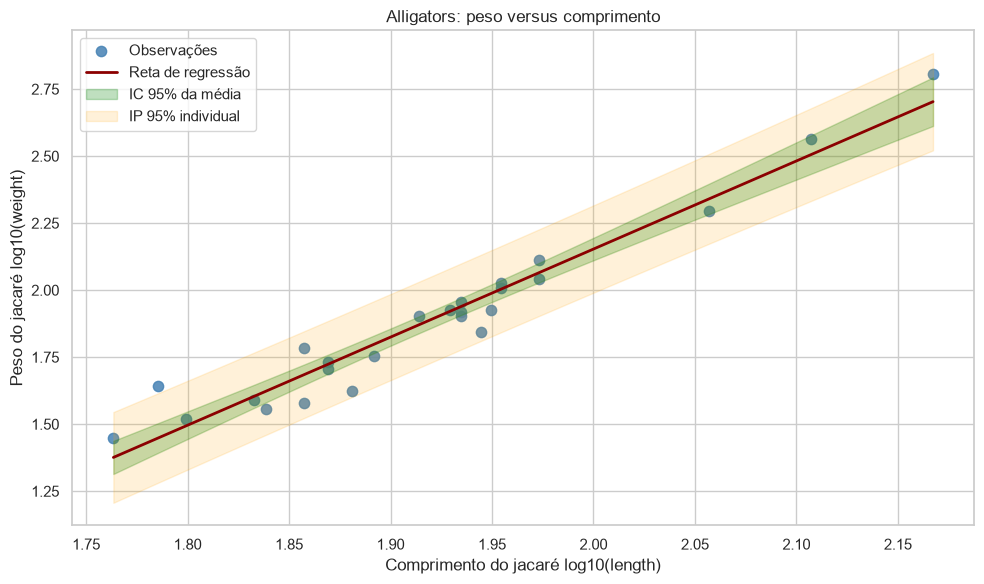

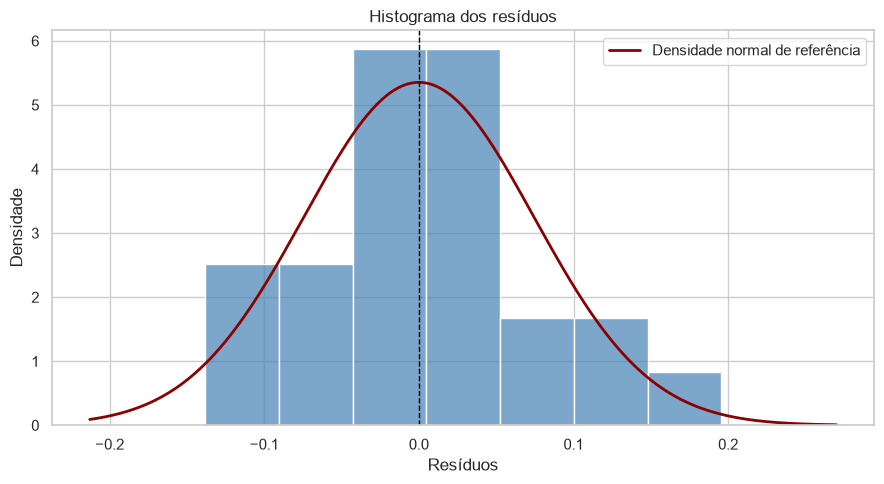

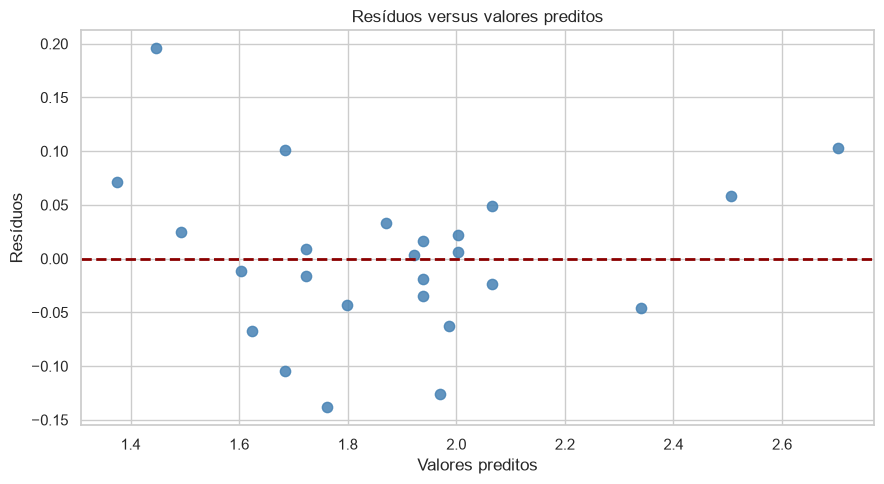

<Figure size 700x700 with 0 Axes>

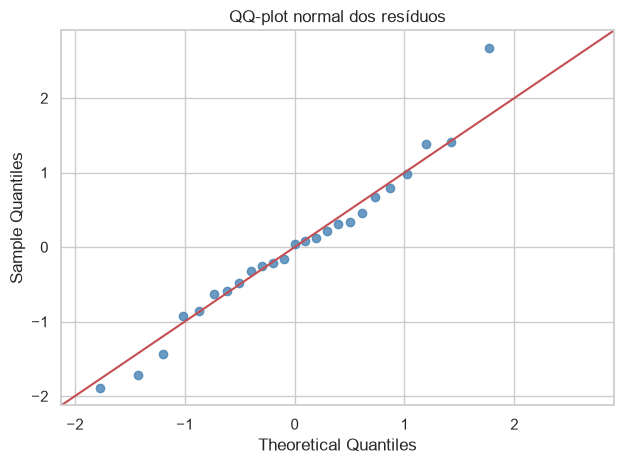


TESTE DE BREUSCH-PAGAN (COMPLEMENTAR)
Estatística LM: 1.1327
P-valor LM: 0.2872
Não há evidência estatística suficiente de heterocedasticidade (5%).


In [17]:
# Nesse caso, foi percebido que a transformação logarítmica de base 10 nas duas variáveis produziu um resultado melhor. Com isso, os novos gráficos são:
df["length"] = np.log10(df["length"])
df["weight"] = np.log10(df["weight"])

X = sm.add_constant(df["length"])
Y = df["weight"]

modelo = sm.OLS(Y, X).fit()

df["predito"] = modelo.fittedvalues
df["residuo"] = modelo.resid

print("\nRESULTADOS DA REGRESSÃO LINEAR")
print(modelo.summary())

tabela_coef = pd.DataFrame({
    "Coeficiente": modelo.params,
    "Erro-padrão": modelo.bse,
    "Estatística t": modelo.tvalues,
    "P-valor": modelo.pvalues,
    "IC 95% inferior": modelo.conf_int()[0],
    "IC 95% superior": modelo.conf_int()[1]
})

print("\nCOEFICIENTES E INTERVALOS DE CONFIANÇA")
display(tabela_coef.round(4))

print(f"R²: {modelo.rsquared:.4f}")
print(f"R² ajustado: {modelo.rsquared_adj:.4f}")

x_grade = np.linspace(df["length"].min(), df["length"].max(), 200)

X_grade = sm.add_constant(x_grade)

previsoes = modelo.get_prediction(X_grade).summary_frame(alpha=0.05)

plt.figure(figsize=(10, 6))

plt.scatter(
    df["length"], df["weight"],
    color="steelblue", s=55, alpha=0.85,
    label="Observações"
)

plt.plot(
    x_grade, previsoes["mean"],
    color="darkred", linewidth=2,
    label="Reta de regressão"
)

plt.fill_between(
    x_grade,
    previsoes["mean_ci_lower"],
    previsoes["mean_ci_upper"],
    color="green", alpha=0.25,
    label="IC 95% da média"
)

plt.fill_between(
    x_grade,
    previsoes["obs_ci_lower"],
    previsoes["obs_ci_upper"],
    color="orange", alpha=0.15,
    label="IP 95% individual"
)

plt.xlabel("Comprimento do jacaré log10(length)")
plt.ylabel("Peso do jacaré log10(weight)")
plt.title("Alligators: peso versus comprimento")
plt.legend()
plt.tight_layout()
plt.show()

residuos = df["residuo"].to_numpy()

media_res = residuos.mean()
desvio_res = residuos.std(ddof=1)

plt.figure(figsize=(9, 5))

sns.histplot(
    residuos, stat="density",
    bins="auto", color="steelblue",
    edgecolor="white", alpha=0.7
)

if desvio_res > 0:
    grade_res = np.linspace(
        residuos.min() - desvio_res,
        residuos.max() + desvio_res, 300
    )

    plt.plot(
        grade_res,
        norm.pdf(grade_res, loc=media_res, scale=desvio_res),
        color="darkred", linewidth=2,
        label="Densidade normal de referência"
    )

plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Resíduos")
plt.ylabel("Densidade")
plt.title("Histograma dos resíduos")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))

plt.scatter(
    df["predito"], df["residuo"],
    color="steelblue", s=55, alpha=0.85
)

plt.axhline(0, color="darkred", linestyle="--", linewidth=2)

plt.xlabel("Valores preditos")
plt.ylabel("Resíduos")
plt.title("Resíduos versus valores preditos")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 7))

sm.qqplot(
    residuos, line="45", fit=True,
    markerfacecolor="steelblue",
    markeredgecolor="steelblue",
    alpha=0.8
)

plt.title("QQ-plot normal dos resíduos")
plt.tight_layout()
plt.show()

bp = het_breuschpagan(modelo.resid, modelo.model.exog)

print("\nTESTE DE BREUSCH-PAGAN (COMPLEMENTAR)")
print(f"Estatística LM: {bp[0]:.4f}")
print(f"P-valor LM: {bp[1]:.4f}")

if bp[1] < 0.05:
    print("Há evidência estatística de heterocedasticidade (5%).")
else:
    print("Não há evidência estatística suficiente de heterocedasticidade (5%).")
